# IMPORTS

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
DATA_DIR = Path("../data/raw/metal_nut").resolve()

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

print("Dataset found:", DATA_DIR.exists())
print("Dataset path:", DATA_DIR)

# README visualizations are saved here (not ignored by Git).
ASSETS_DIR = Path("../assets").resolve()
ASSETS_DIR.mkdir(parents=True, exist_ok=True)
print("Figures will be saved to:", ASSETS_DIR)


Dataset found: True
Dataset path: /Users/chkhai/Documents/projects/inspectAI/data/raw/metal_nut
Figures will be saved to: /Users/chkhai/Documents/projects/inspectAI/assets


# EXPLORE DATASET 

In [3]:
# Count image files, excluding hidden files such as .DS_Store
image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}

for split in ["train", "test", "ground_truth"]:
    split_dir = DATA_DIR / split
    print(f"\n{split.upper()}")

    for folder in sorted(split_dir.iterdir()):
        if folder.is_dir():
            images = [
                p for p in folder.iterdir()
                if p.is_file() and p.suffix.lower() in image_extensions
            ]
            print(f"  {folder.name}: {len(images)} images")


TRAIN
  good: 220 images

TEST
  bent: 25 images
  color: 22 images
  flip: 23 images
  good: 22 images
  scratch: 23 images

GROUND_TRUTH
  bent: 25 images
  color: 22 images
  flip: 23 images
  scratch: 23 images


# Visualize normal and defective nuts

Saved: /Users/chkhai/Documents/projects/inspectAI/assets/dataset_examples.png


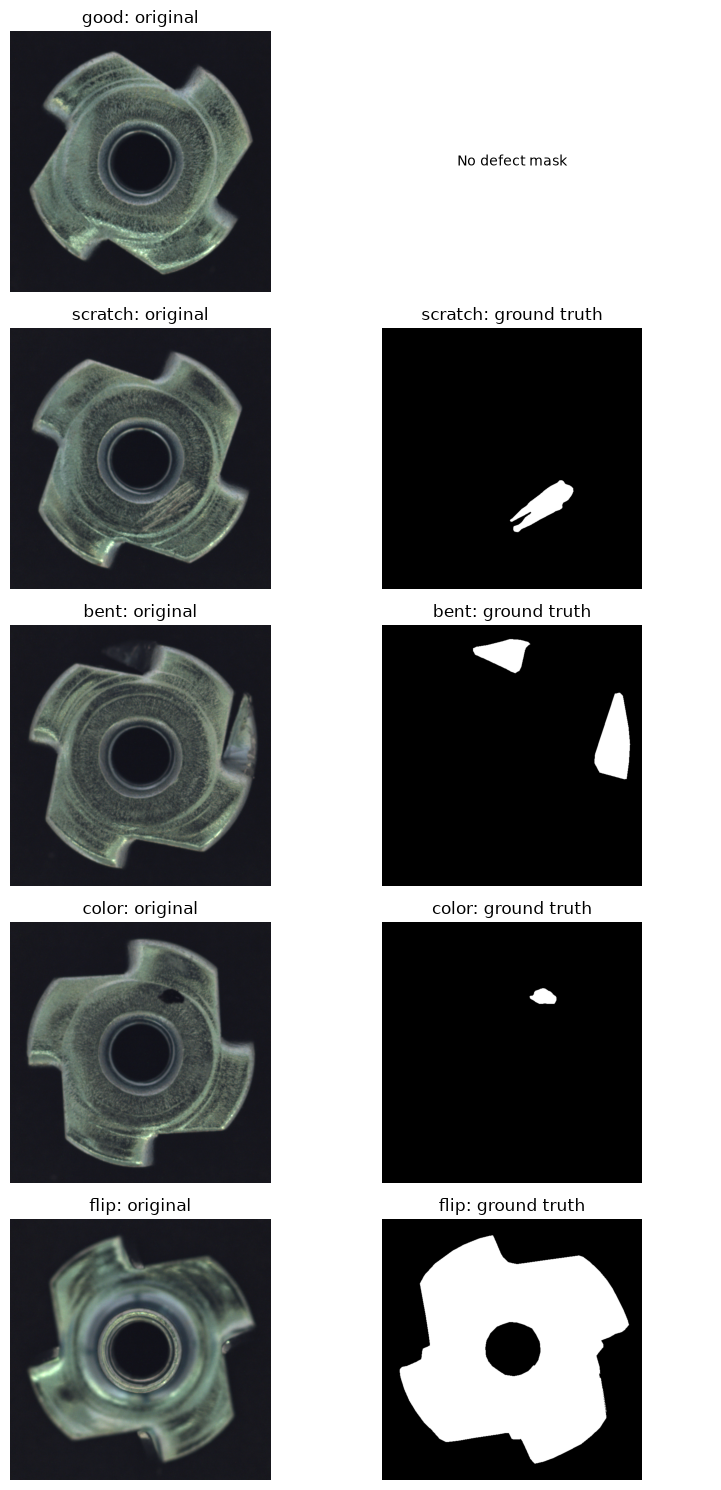

In [4]:
categories = ["good", "scratch", "bent", "color", "flip"]

fig, axes = plt.subplots(len(categories), 2, figsize=(8, 15))

for i, category in enumerate(categories):
    image_dir = DATA_DIR / ("train" if category == "good" else "test") / category

    images = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    image_path = images[0]
    image = Image.open(image_path).convert("RGB")

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"{category}: original")
    axes[i, 0].axis("off")

    if category == "good":
        axes[i, 1].text(0.5, 0.5, "No defect mask", ha="center", va="center")
        axes[i, 1].axis("off")
    else:
        mask_path = DATA_DIR / "ground_truth" / category / f"{image_path.stem}_mask.png"

        if mask_path.exists():
            mask = Image.open(mask_path).convert("L")
            axes[i, 1].imshow(mask, cmap="gray")
            axes[i, 1].set_title(f"{category}: ground truth")
        else:
            axes[i, 1].text(0.5, 0.5, f"Mask not found:\n{mask_path.name}",
                            ha="center", va="center")
            axes[i, 1].set_title(category)

        axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(ASSETS_DIR / "dataset_examples.png", dpi=150, bbox_inches="tight")
print("Saved:", ASSETS_DIR / "dataset_examples.png")
plt.show()

# Image & Mask Dimensions

In [5]:
image_path = sorted(
    p for p in (DATA_DIR / "test/scratch").iterdir()
    if p.suffix.lower() == ".png"
)[0]

mask_path = DATA_DIR / "ground_truth/scratch" / f"{image_path.stem}_mask.png"

image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path).convert("L"))

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask pixel values:", np.unique(mask))
print("Defect pixel percentage:", round((mask > 0).mean() * 100, 3), "%")

Image shape: (700, 700, 3)
Mask shape: (700, 700)
Mask pixel values: [  0 255]
Defect pixel percentage: 1.898 %


# Image Properties

good     | shape=(700, 700, 3) | min=13 | max=255 | mean pixel value=61.6
scratch  | shape=(700, 700, 3) | min=14 | max=255 | mean pixel value=57.6
bent     | shape=(700, 700, 3) | min=13 | max=255 | mean pixel value=58.7
color    | shape=(700, 700, 3) | min=13 | max=255 | mean pixel value=56.4
flip     | shape=(700, 700, 3) | min=13 | max=255 | mean pixel value=62.3
Saved: /Users/chkhai/Documents/projects/inspectAI/assets/image_properties.png


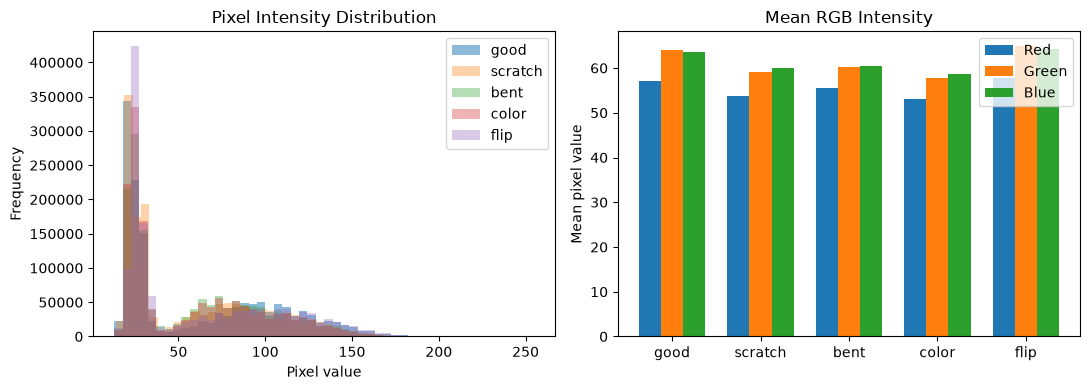

In [6]:
categories = ["good", "scratch", "bent", "color", "flip"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for category in categories:
    split = "train" if category == "good" else "test"
    folder = DATA_DIR / split / category
    image_path = next(
        p for p in sorted(folder.iterdir())
        if p.is_file() and p.suffix.lower() == ".png"
    )

    image = np.array(Image.open(image_path).convert("RGB"))

    print(
        f"{category:8s} | shape={image.shape} "
        f"| min={image.min()} | max={image.max()} "
        f"| mean pixel value={image.mean():.1f}"
    )

    if category == "good":
        axes[0].hist(
            image.ravel(), bins=50, alpha=0.5, label=category
        )
    else:
        axes[0].hist(
            image.ravel(), bins=50, alpha=0.35, label=category
        )

axes[0].set_title("Pixel Intensity Distribution")
axes[0].set_xlabel("Pixel value")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# Compare RGB channel means across categories
labels, means = [], []

for category in categories:
    split = "train" if category == "good" else "test"
    folder = DATA_DIR / split / category
    image_path = next(
        p for p in sorted(folder.iterdir())
        if p.is_file() and p.suffix.lower() == ".png"
    )

    image = np.array(Image.open(image_path).convert("RGB"))
    labels.append(category)
    means.append(image.mean(axis=(0, 1)))

means = np.array(means)
x = np.arange(len(labels))
width = 0.25

for i, channel in enumerate(["Red", "Green", "Blue"]):
    axes[1].bar(x + (i - 1) * width, means[:, i],
                width, label=channel)

axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title("Mean RGB Intensity")
axes[1].set_ylabel("Mean pixel value")
axes[1].legend()

plt.tight_layout()
plt.savefig(ASSETS_DIR / "image_properties.png", dpi=150, bbox_inches="tight")
print("Saved:", ASSETS_DIR / "image_properties.png")
plt.show()

# Defect Size Distribution

scratch  | n=23 | mean=  5.90% | median=  5.54% | min=  1.90% | max= 12.30%
bent     | n=25 | mean=  2.04% | median=  1.87% | min=  0.71% | max=  4.70%
color    | n=22 | mean=  2.36% | median=  2.09% | min=  0.44% | max=  6.57%
flip     | n=23 | mean= 48.22% | median= 48.17% | min= 47.85% | max= 48.72%
Saved: /Users/chkhai/Documents/projects/inspectAI/assets/defect_distribution.png


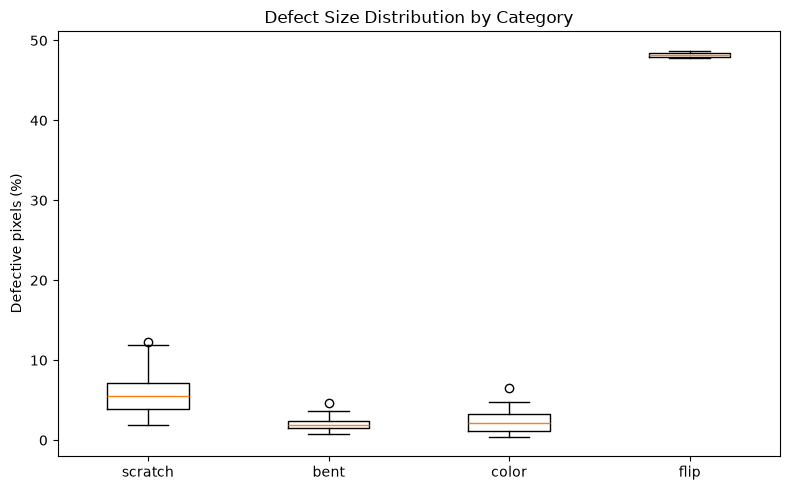

In [7]:
defect_percentages = {}

for category in ["scratch", "bent", "color", "flip"]:
    mask_dir = DATA_DIR / "ground_truth" / category

    for mask_path in sorted(mask_dir.iterdir()):
        if mask_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        mask = np.array(Image.open(mask_path).convert("L"))
        defect_percentage = (mask > 0).mean() * 100

        defect_percentages.setdefault(category, []).append(
            defect_percentage
        )

for category, values in defect_percentages.items():
    print(
        f"{category:8s} | n={len(values):2d} "
        f"| mean={np.mean(values):6.2f}% "
        f"| median={np.median(values):6.2f}% "
        f"| min={np.min(values):6.2f}% "
        f"| max={np.max(values):6.2f}%"
    )

plt.figure(figsize=(8, 5))
plt.boxplot(
    [defect_percentages[c] for c in defect_percentages],
    tick_labels=list(defect_percentages.keys())
)
plt.ylabel("Defective pixels (%)")
plt.title("Defect Size Distribution by Category")
plt.tight_layout()
plt.savefig(ASSETS_DIR / "defect_distribution.png", dpi=150, bbox_inches="tight")
print("Saved:", ASSETS_DIR / "defect_distribution.png")
plt.show()

# Normal Image Variation

Saved: /Users/chkhai/Documents/projects/inspectAI/assets/normal_variation.png


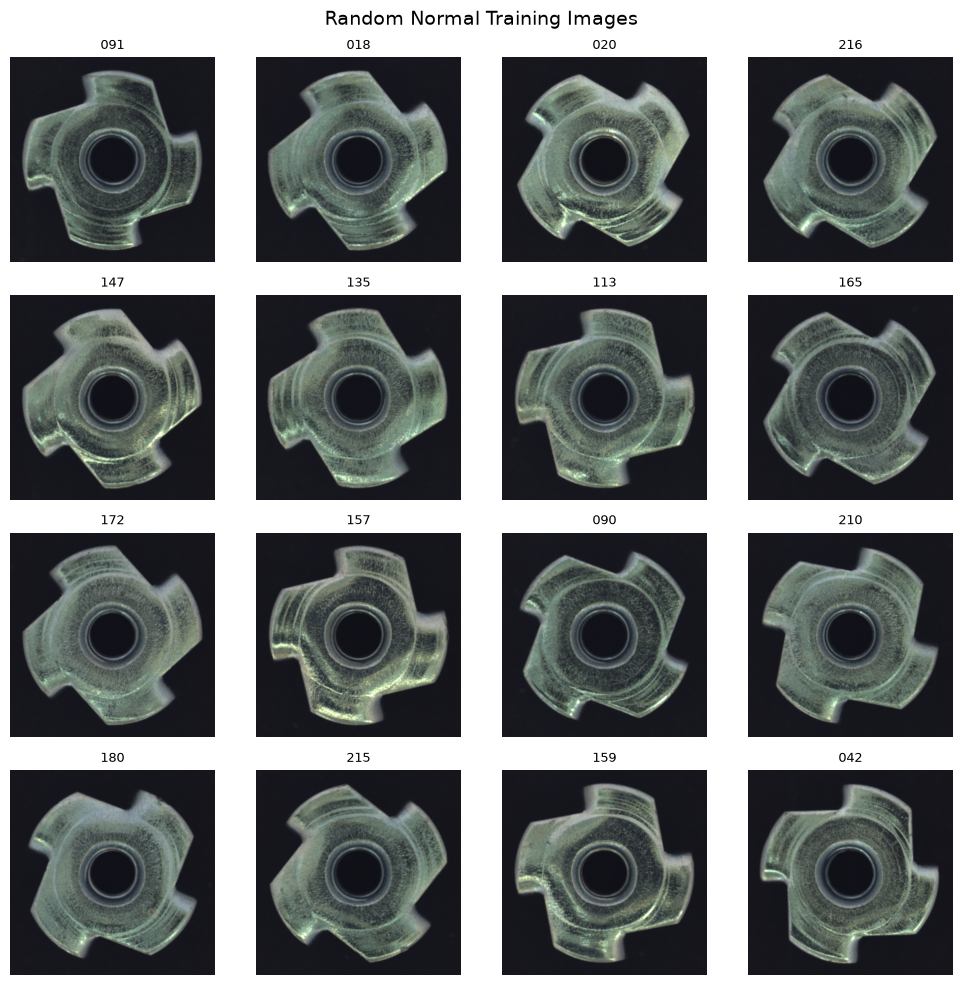

In [8]:
normal_dir = DATA_DIR / "train" / "good"

normal_paths = sorted(
    p for p in normal_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
)

rng = np.random.default_rng(42)
selected_indices = rng.choice(len(normal_paths), size=16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for ax, idx in zip(axes.flat, selected_indices):
    image = Image.open(normal_paths[idx]).convert("RGB")

    ax.imshow(image)
    ax.set_title(normal_paths[idx].stem, fontsize=9)
    ax.axis("off")

plt.suptitle("Random Normal Training Images", fontsize=14)
plt.tight_layout()
plt.savefig(ASSETS_DIR / "normal_variation.png", dpi=150, bbox_inches="tight")
print("Saved:", ASSETS_DIR / "normal_variation.png")
plt.show()

# Dataset Integrity Checks

In [9]:
from collections import Counter

image_sizes = Counter()
mask_sizes = Counter()
mask_values = set()

missing_masks = []
invalid_masks = []
unreadable_files = []

image_count = 0
mask_count = 0

# Check training and test images
for split in ["train", "test"]:
    for path in sorted((DATA_DIR / split).rglob("*")):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(path) as img:
                img.load()
                image_sizes[img.size] += 1
                image_count += 1

            # Every defective test image should have a mask
            if split == "test" and path.parent.name != "good":
                mask_path = (
                    DATA_DIR / "ground_truth"
                    / path.parent.name
                    / f"{path.stem}_mask.png"
                )

                if not mask_path.exists():
                    missing_masks.append(str(path.relative_to(DATA_DIR)))

        except Exception as e:
            unreadable_files.append((str(path), str(e)))


# Check ground-truth masks
for path in sorted((DATA_DIR / "ground_truth").rglob("*")):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    try:
        with Image.open(path) as img:
            img.load()
            mask_sizes[img.size] += 1
            mask = np.array(img.convert("L"))
            mask_count += 1

            values = np.unique(mask)
            mask_values.update(values.tolist())

            if not np.isin(values, [0, 255]).all():
                invalid_masks.append(str(path.relative_to(DATA_DIR)))

    except Exception as e:
        unreadable_files.append((str(path), str(e)))


print("Total images:", image_count)
print("Total masks:", mask_count)
print("Image dimensions:", dict(image_sizes))
print("Mask dimensions:", dict(mask_sizes))
print("Mask pixel values:", sorted(mask_values))

print("\nMissing masks:", len(missing_masks))
print("Invalid masks:", len(invalid_masks))
print("Unreadable files:", len(unreadable_files))

Total images: 335
Total masks: 93
Image dimensions: {(700, 700): 335}
Mask dimensions: {(700, 700): 93}
Mask pixel values: [0, 255]

Missing masks: 0
Invalid masks: 0
Unreadable files: 0


# EDA Summary and Key Findings

- **Dataset:** 220 normal training images and 115 test images (22 normal, 93 defective).
- **Image properties:** All 335 images are RGB with a resolution of 700 × 700 pixels.
- **Anomaly types:** Scratch, bent, color, and flip.
- **Normal variation:** Normal nuts exhibit differences in rotation, lighting, and surface texture.
- **Defect sizes:** Localized defects occupy relatively small regions (2–6% on average), while flip anomalies cover approximately 48% of image pixels.
- **Pixel distributions:** Normal and defective images show substantial overlap in pixel intensity distributions in the sampled examples.
- **Data integrity:** All 93 ground-truth masks are present, dimensions are consistent, masks contain only binary values (0 and 255), and no unreadable files were found.

## Modeling Implications

- Train the anomaly detector using only normal images.
- Use pretrained CNN features to capture meaningful visual patterns beyond raw pixel intensities.
- Account for natural variation in normal images to reduce false positives.
- Preserve spatial information to detect small, localized defects.
- Evaluate both image-level anomaly detection and pixel-level defect localization.
- Analyze performance separately for each defect category.

**Next step:** Build a feature-based anomaly detection baseline and compare its performance against PatchCore.